In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

In [2]:
from torchvision import datasets, transforms

In [3]:
tranforms = transforms.ToTensor()

In [4]:
train_data = datasets.MNIST(root="data", train=True, download=True, transform=tranforms)
test_data = datasets.MNIST(root="data", train=False, download=True, transform=tranforms)

In [5]:
train_data[1][0].shape

torch.Size([1, 28, 28])

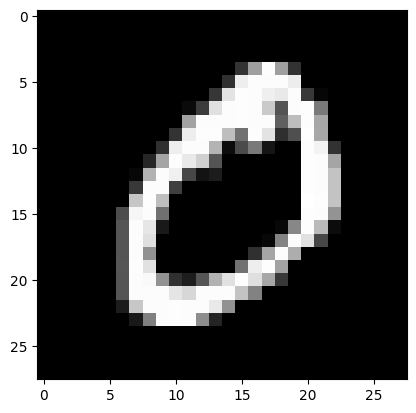

In [6]:
plt.imshow(train_data[1][0].squeeze(),cmap = 'gray')

In [7]:
train_data[1][1]

0

In [8]:
train_data[1][0].shape

torch.Size([1, 28, 28])

In [9]:
train_data[1][0].squeeze().shape

torch.Size([28, 28])

In [10]:
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=True)

In [ ]:
(batch_size, 1,28,28)

In [ ]:
60,000 / 128 - Updates

In [13]:
images, labels = next(iter(train_loader))

In [14]:
images.shape #RGB - 128, 3, 28, 28

torch.Size([128, 1, 28, 28])

In [15]:
labels.shape

torch.Size([128])

In [16]:
28*28

784

In [17]:
#784 -> 128 -> 10 Probability (Cross-Entropy)

In [18]:
activation_choices = {
    "ReLu":nn.ReLU,
    "Tanh":nn.Tanh,
    "Sigmoid":nn.Sigmoid,
    "LeakyReLU":nn.LeakyReLU,
    "ELU": nn.ELU,
    "GELU":nn.GELU,
}

In [19]:
def make_model(activation_name="ReLU"):
  return nn.Sequential(
      nn.Flatten(),
      nn.Linear(28*28, 128),
      activation_choices[activation_name](),
      nn.Linear(128,10)
  )

Model = make_model("ReLu")

In [20]:
loss_fn = nn.CrossEntropyLoss() #Cost is Categorical Cross entropy

In [ ]:
# My model has to see all the 60,000 images for 1 epoch to complete
Training dataset = 60000 / batch size = 128

In [22]:
def train_model(model,optimizer, loader, epochs=2):
  history = []
  for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    model.train()
    total_loss = 0

    for images, labels in loader:
      predictions = model(images) #First Forward pass over the batch
      loss = loss_fn(predictions, labels) #Calculate the loss

      optimizer.zero_grad() #Clearing any residual / old gradients
      loss.backward() #Computing backpropagation
      optimizer.step() #Updating the weights

      total_loss += loss.item()
    avg_loss = total_loss / len(loader.dataset)
    history.append(avg_loss)
    print(f"Loss: {avg_loss}")
  return history

In [23]:
def test_accuracy(model):
  model.eval()
  correct = 0
  total = 0

  with torch.no_grad():
    for images, labels in test_loader:
      predictions = model(images).argmax(dim=1)
      correct += (predictions == labels).sum().item()
      total += predictions.size(0)
  return 100 * correct / total

In [24]:
model = make_model("ReLu")

In [27]:
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

losses = train_model(model, optimizer, train_loader, epochs=2)

Epoch 1/2
Loss: 0.0032302272342145445
Epoch 2/2
Loss: 0.001469262276093165


In [26]:
test_images, test_labels = next(iter(test_loader))

model.eval()
with torch.no_grad(): #dont calculate gradients for this operation
  predictions = model(test_images).argmax(dim=1)

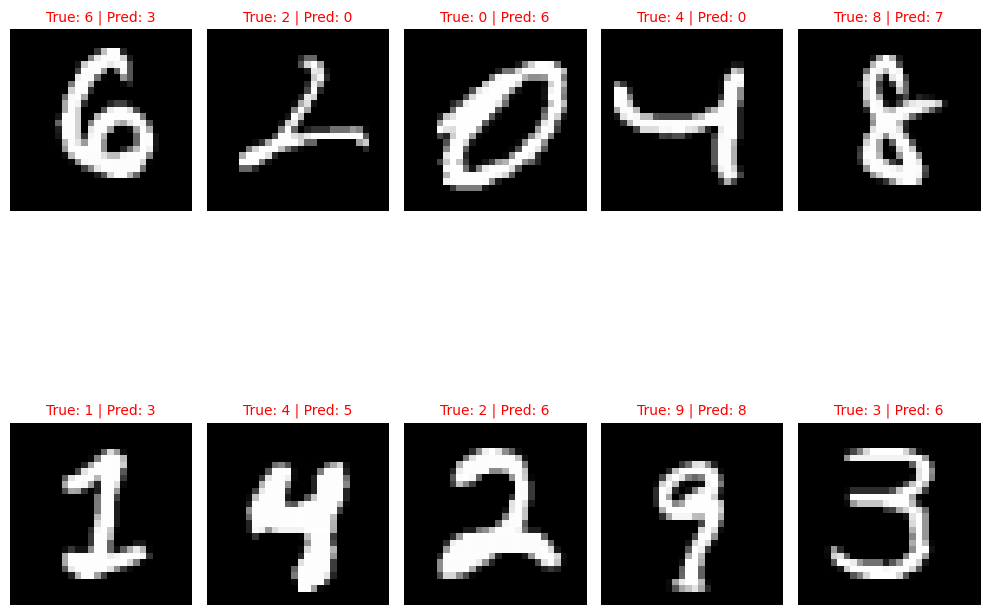

In [29]:
plt.figure(figsize=(10,10))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(test_images[i].squeeze(),cmap='gray')
  right = predictions[i].item() == test_labels[i].item()
  colour = 'green' if right else 'red'

  plt.title(f"True: {test_labels[i].item()} | Pred: {predictions[i].item()}",color=colour, fontsize=10)
  plt.axis('off')
plt.tight_layout()
plt.show()

In [32]:
model = make_model("ReLu")
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

losses = train_model(model, optimizer, train_loader, epochs=10)

Epoch 1/10
Loss: 0.003282563900699218
Epoch 2/10
Loss: 0.0015017513720939556
Epoch 3/10
Loss: 0.0010667477568921944
Epoch 4/10
Loss: 0.0008230140888442596
Epoch 5/10
Loss: 0.0006576071463214855
Epoch 6/10
Loss: 0.0005462993316662808
Epoch 7/10
Loss: 0.0004572209075869371
Epoch 8/10
Loss: 0.0003895337283999349
Epoch 9/10
Loss: 0.00033175165654780964
Epoch 10/10
Loss: 0.00028666694683488457


In [33]:
test_images, test_labels = next(iter(test_loader))

model.eval()
with torch.no_grad(): #dont calculate gradients for this operation
  predictions = model(test_images).argmax(dim=1)

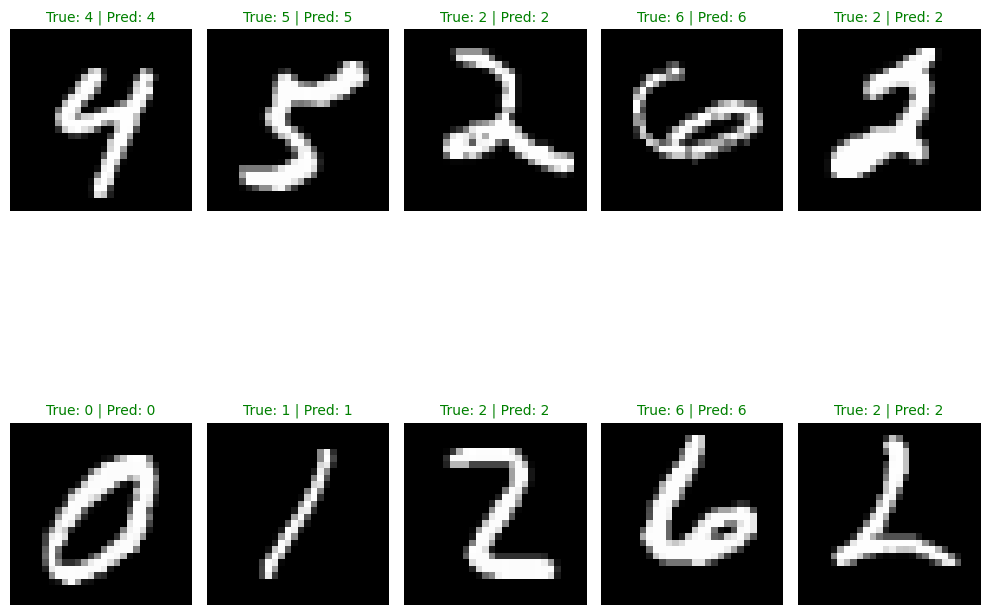

In [34]:
plt.figure(figsize=(10,10))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(test_images[i].squeeze(),cmap='gray')
  right = predictions[i].item() == test_labels[i].item()
  colour = 'green' if right else 'red'

  plt.title(f"True: {test_labels[i].item()} | Pred: {predictions[i].item()}",color=colour, fontsize=10)
  plt.axis('off')
plt.tight_layout()
plt.show()


 Optimizer: SGD
Epoch 1/2
Loss: 0.01762847477197647
Epoch 2/2
Loss: 0.01691311349074046
Test accuracy: 55.34

 Optimizer: Momentum
Epoch 1/2
Loss: 0.013762342250347137
Epoch 2/2
Loss: 0.006288407587011655
Test accuracy: 86.27

 Optimizer: RMSprop
Epoch 1/2
Loss: 0.002551845173413555
Epoch 2/2
Loss: 0.0013802673504998287
Test accuracy: 95.82

 Optimizer: Adam
Epoch 1/2
Loss: 0.0032648572207738956
Epoch 2/2
Loss: 0.001509534160171946
Test accuracy: 95.54

 Optimizer: AdamW
Epoch 1/2
Loss: 0.0032543145645409824
Epoch 2/2
Loss: 0.001531326188147068
Test accuracy: 95.21


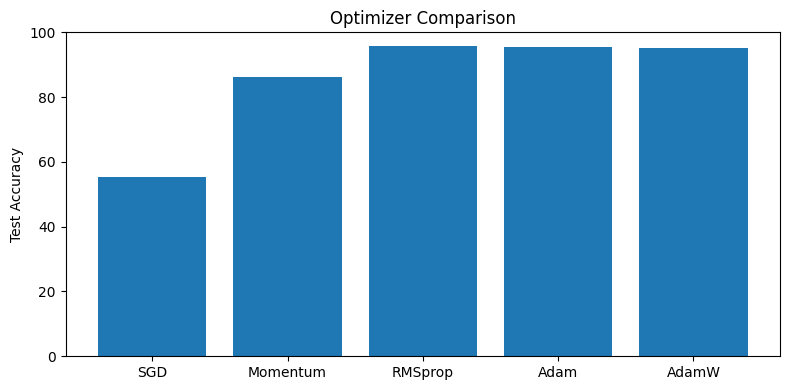

In [36]:
optimizer_results = {}

for name in ['SGD','Momentum','RMSprop','Adam',"AdamW"]:
  print("\n Optimizer:", name)
  comparison_model = make_model("ReLu")

  if name =="SGD":
    optimizer = torch.optim.SGD(comparison_model.parameters(),lr=0.001)
  elif name == "Momentum":
    optimizer = torch.optim.SGD(comparison_model.parameters(),lr=0.001, momentum=0.9)
  elif name == "RMSprop":
    optimizer = torch.optim.RMSprop(comparison_model.parameters(),lr=0.001)
  elif name == "Adam":
    optimizer = torch.optim.Adam(comparison_model.parameters(),lr = 0.001)
  elif name == "AdamW":
    optimizer = torch.optim.AdamW(comparison_model.parameters(),lr = 0.001,weight_decay=0.001)

  train_model(comparison_model, optimizer, train_loader, epochs=2)
  optimizer_results[name] = test_accuracy(comparison_model)
  print(f"Test accuracy: {optimizer_results[name]:.2f}")

plt.figure(figsize=(8,4))
plt.bar(optimizer_results.keys(), optimizer_results.values())
plt.ylabel("Test Accuracy")
plt.title("Optimizer Comparison")
plt.ylim(0,100)
plt.tight_layout()
plt.show()